# 06 - XGBoost

In this notebook I build the XGBoost model with all 11 features, using the `mlforecast` library.

`mlforecast` builds the past load features (lags and rolling means) by itself.
For hours 2-24 of each forecast it puts its own forecasts back in as lags (recursive forecasting).
The calendar and temperature features are given as extra columns.

### 1. Import libraries and load the data

In [1]:
import os
import time

import pandas as pd
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.lag_transforms import RollingMean
from xgboost import XGBRegressor

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"
os.makedirs(forecast_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)

In [2]:
data = pd.read_csv("../datasets/processed/gb_features_2015_2019.csv")

# the Nixtla libraries need three columns: unique_id, ds (time) and y (value to forecast)
df = pd.DataFrame()
df["unique_id"] = ["GB"] * len(data)
df["ds"] = pd.to_datetime(data["time"]).dt.tz_localize(None)   # time in UTC, without the time zone label
df["y"] = data["load"]

# calendar and temperature features (known in advance for the next 24 hours)
extra_features = ["hour", "day_of_week", "month", "is_weekend", "is_holiday", "temperature"]
for col in extra_features:
    df[col] = data[col]

df.head()

,unique_id,ds,y,hour,day_of_week,month,is_weekend,is_holiday,temperature
0,GB,2015-01-08 00:00:00,32593.0,0,3,1,0,0,8.582
1,GB,2015-01-08 01:00:00,31607.0,1,3,1,0,0,8.491
2,GB,2015-01-08 02:00:00,30136.0,2,3,1,0,0,8.333
3,GB,2015-01-08 03:00:00,29286.0,3,3,1,0,0,8.099
4,GB,2015-01-08 04:00:00,27746.0,4,3,1,0,0,7.862


### How the forecasts are made

The same setup is used for every model:
- The model is trained on data **before 2019**.
- Then, for **every day of 2019** (365 days), it forecasts the **next 24 hours** from midnight (UTC).
- Each day it uses the real data up to that midnight, but the model itself is not trained again.

This gives 365 × 24 = 8,760 forecasts for each model. The library function `cross_validation` does this for me.

### 2. The model setup

- `lags=[1, 24, 168]` gives `lag_1`, `lag_24` and `lag_168`
- `RollingMean` on lag 1 gives `rolling_mean_24` and `rolling_mean_168`
- the 6 extra columns give the calendar features and temperature

Together these are the 11 features from notebook 04.

In [3]:
def make_model(max_depth, learning_rate):
    xgb = XGBRegressor(
        n_estimators=500,
        max_depth=max_depth,
        learning_rate=learning_rate,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
    )
    model = MLForecast(
        models={"XGBoost": xgb},
        freq="h",
        lags=[1, 24, 168],
        lag_transforms={1: [RollingMean(window_size=24), RollingMean(window_size=168)]},
    )
    return model

### 3. Tuning on the validation year (2018)

I try a few settings. Each one is trained on 2015-2017 and tested on every day of 2018. The test year 2019 is not used here.

In [4]:
until_2018 = df[df["ds"] < "2019-01-01"]

results = []
for max_depth in [4, 6, 8]:
    for learning_rate in [0.05, 0.1]:
        model = make_model(max_depth, learning_rate)
        cv = model.cross_validation(df=until_2018, h=24, step_size=24, n_windows=365, refit=False, static_features=[])
        mae = (cv["y"] - cv["XGBoost"]).abs().mean()
        results.append([max_depth, learning_rate, mae])
        print("max_depth", max_depth, "learning_rate", learning_rate, "-> MAE", round(mae))

tuning = pd.DataFrame(results, columns=["max_depth", "learning_rate", "MAE_2018"])
tuning.to_csv(tables_folder + "/xgboost_tuning.csv", index=False)

max_depth 4 learning_rate 0.05 -> MAE 1017


max_depth 4 learning_rate 0.1 -> MAE 1013


max_depth 6 learning_rate 0.05 -> MAE 980


max_depth 6 learning_rate 0.1 -> MAE 1006


max_depth 8 learning_rate 0.05 -> MAE 987


max_depth 8 learning_rate 0.1 -> MAE 1020


In [5]:
best = tuning.sort_values("MAE_2018").iloc[0]
best_depth = int(best["max_depth"])
best_lr = best["learning_rate"]

print("Best setting: max_depth =", best_depth, ", learning_rate =", best_lr)

Best setting: max_depth = 6 , learning_rate = 0.05


### 4. Forecast 2019 with the best setting
The model is now trained on all data before 2019 (2015-2018).

In [6]:
start = time.time()

xgb_model = make_model(best_depth, best_lr)
xgb_cv = xgb_model.cross_validation(df=df, h=24, step_size=24, n_windows=365, refit=False, static_features=[])

xgb_seconds = time.time() - start
print("Time:", round(xgb_seconds), "seconds")

xgb_mae = (xgb_cv["y"] - xgb_cv["XGBoost"]).abs().mean()
print("XGBoost MAE on 2019:", round(xgb_mae), "MW")

Time: 20 seconds
XGBoost MAE on 2019: 1081 MW


### 5. Feature importance
Which features does XGBoost use most?

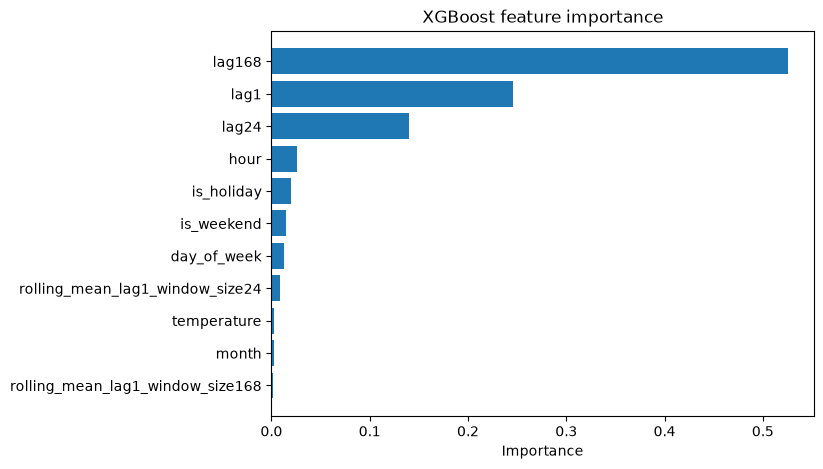

,feature,importance
8,lag168,0.525665
6,lag1,0.245674
7,lag24,0.139758
0,hour,0.025715
4,is_holiday,0.019747
3,is_weekend,0.014626
1,day_of_week,0.013243
9,rolling_mean_lag1_window_size24,0.008937
5,temperature,0.002788
2,month,0.002189


In [7]:
# train the same model on data before 2019 to read the importance
xgb_model.fit(until_2018, static_features=[])

names = xgb_model.ts.features_order_
importance = xgb_model.models_["XGBoost"].feature_importances_

importance_table = pd.DataFrame({"feature": names, "importance": importance})
importance_table = importance_table.sort_values("importance")

plt.figure(figsize=(7, 5))
plt.barh(importance_table["feature"], importance_table["importance"])
plt.title("XGBoost feature importance")
plt.xlabel("Importance")
plt.savefig(figures_folder + "/06_xgboost_importance.png")
plt.show()

importance_table.sort_values("importance", ascending=False)

The names are the library's names: `lag1` = `lag_1`, `rolling_mean_lag1_window_size24` = `rolling_mean_24`, and so on.

### 6. Plot one week

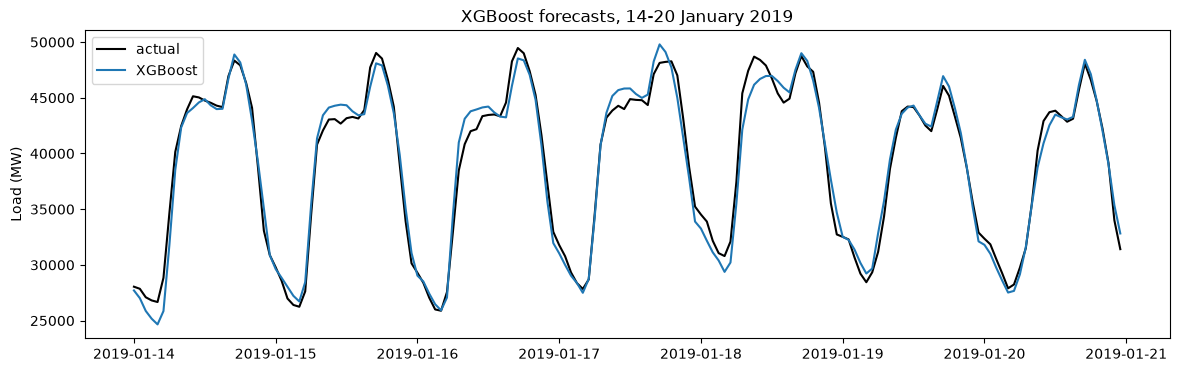

In [8]:
week = (xgb_cv["ds"] >= "2019-01-14") & (xgb_cv["ds"] < "2019-01-21")

plt.figure(figsize=(14, 4))
plt.plot(xgb_cv[week]["ds"], xgb_cv[week]["y"], label="actual", color="black")
plt.plot(xgb_cv[week]["ds"], xgb_cv[week]["XGBoost"], label="XGBoost")
plt.title("XGBoost forecasts, 14-20 January 2019")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/06_xgboost_week.png")
plt.show()

### 7. Save

In [9]:
out = pd.DataFrame()
out["time"] = xgb_cv["ds"]
out["cutoff"] = xgb_cv["cutoff"]
out["actual"] = xgb_cv["y"]
out["forecast"] = xgb_cv["XGBoost"]
out.to_csv(forecast_folder + "/xgboost.csv", index=False)

pd.DataFrame({"model": ["XGBoost"], "seconds": [xgb_seconds]}).to_csv(tables_folder + "/time_xgboost.csv", index=False)
print("Saved")

Saved


### 8. Save the trained model for the dashboard

The model trained on data before 2019 (from section 5) is saved, together with the order of its features.
The dashboard uses it to make new forecasts.

In [10]:
models_folder = "../results/models"
os.makedirs(models_folder, exist_ok=True)

xgb_model.models_["XGBoost"].save_model(models_folder + "/xgboost.json")

pd.Series(names).to_csv(models_folder + "/xgboost_features.csv", index=False, header=["feature"])
print("Saved the model and", len(names), "feature names")

Saved the model and 11 feature names


### Summary

- XGBoost with the 11 features, recursive forecasting for hours 2-24
- Settings chosen on 2018 only
- Forecasts saved in `results/forecasts/xgboost.csv`

**Next:** notebook 07 - LSTM and PatchTST.